# CSE5280 — Evacuation Simulation (Three-Floor Building)
**Florida Institute of Technology**
*Bryan Bermudez | Spring 2026*

## Table of Contents

1. [Overview & Introduction](#1-overview--introduction)
2. [Mathematical Background](#2-mathematical-background)
3. [Utility & Math Functions](#3-utility--math-functions)
4. [Ramp & 3D Geometry Functions](#4-ramp--3d-geometry-functions)
5. [Cost Terms — Surface Adherence & Full Cost](#5-cost-terms--surface-adherence--full-cost)
6. [Building Visualization](#6-building-visualization)
7. [Simulation — Gradient Descent Evacuation](#7-simulation--gradient-descent-evacuation)
8. [Video Export](#8-video-export)
9. [Discussion & Results](#9-discussion--results)

---

## 1. Overview & Introduction

This notebook implements a multi-particle building evacuation simulation using **gradient descent on a scalar cost function**. N,defualt N being 25, agents are distributed across three floors of a building and each agent follows the negative gradient of a composite cost landscape to navigate toward one of two ground-floor exits.

Everything is done with costs with no hardcoded path dectection, exit dection, wall dectection, etc

The simulation i shown at the bottom using the vedo libarey 

---

## 2. Mathematical Background

### 2.1 Ramp Model

A ramp connects two floors via a continuously-inclined surface. It is defined by a 2D centerline segment $[A, B]$ and a capsule half-width $r$. For any point $P = (x, y)$ we project onto the centerline:

$$t = \frac{(P - A) \cdot v}{v \cdot v}, \qquad v = B - A \tag{4.4, 4.5}$$

The projection is clamped to restrict to the finite ramp segment:

$$u(x, y) = \text{clip}(t,\, 0,\, 1) \tag{4.6}$$

The ramp height interpolates linearly between $z_0$ at $A$ and $z_1$ at $B$:

$$z_{\text{ramp}}(x, y) = z_0 + (z_1 - z_0)\, u(x, y) \tag{4.7}$$

The ramp footprint is a capsule around the centerline:

$$\mathcal{R} = \{(x,y) \mid \text{dist}((x,y),\,[A,B]) \leq r\} \tag{4.9}$$

### 2.2 Cost Function

Each particle with position $\mathbf{p} = (x, y, z)$ minimizes the composite cost:

$$C = C_{\text{goal}} + C_{\text{walls}} + C_{\text{height}} + C_{\text{smoothness}} + C_{\text{repulsion}} \tag{5.6}$$

**Goal attraction — soft-min :** A hard $\min(C_1, C_2)$ :

$$C_{\text{goal}}(\mathbf{p}) = -\tau \log\!\left(\sum_{i=1}^{2} \exp\!\left(-\frac{C_i(\mathbf{p})}{\tau}\right)\right), \qquad C_i(\mathbf{p}) = \|\mathbf{p} - \mathbf{p}^{\text{exit}}_i\|^2 \tag{5.7, 5.9}$$

Temperature $\tau \in [0.5, 1.5]$: smaller $\tau$ sharpens exit selection, larger $\tau$ blends exits more evenly. We use $\tau = 1.0$.

**Wall penalty — quadratic band:**

$$C_{\text{walls}} = \sum_k w_k\, \phi(d_k(\mathbf{p})), \qquad \phi(d) = \tfrac{1}{2}(R - d)^2\; \mathbf{1}[d \leq R] \tag{5.13}$$

**Surface-adherence cost:**

$$C_{\text{height}} = w_h \bigl(z - z_{\text{surf}}(x,y)\bigr)^2 \tag{5.2}$$

$$z_{\text{surf}}(x,y) = (1 - g)\,z_{\text{floor}} + g\,z_{\text{ramp}}(x,y), \qquad g = \begin{cases}1 & (x,y) \in \mathcal{R} \\ 0 & \text{otherwise}\end{cases} \tag{5.3, 5.4}$$

**Smoothness:**

$$C_{\text{smooth}} = \|\mathbf{p}_{k+1} - \mathbf{p}_k\|^2 \tag{5.14}$$

**Agent repulsion:**

$$C_{\text{repulsion}} = \sum_{j \neq i} \phi(\|\mathbf{p}_i - \mathbf{p}_j\|) \tag{5.15}$$

### 2.3 Optimization

Gradient descent with momentum smoothing and step-size capping:

$$\mathbf{v}_{k+1} = \mu\,\mathbf{v}_k - \alpha\,\nabla C(\mathbf{p}_k)$$
$$\mathbf{p}_{k+1} = \mathbf{p}_k + \text{clip}(\mathbf{v}_{k+1},\, -\Delta_{\max},\, \Delta_{\max})$$

Gradients are computed numerically via central finite differences. An agent is evacuated once its $(x,y)$ is within tolerance of either exit on the ground floor.

---

## 3. Utility & Math Functions

The cell below contains foundational geometry and cost helpers carried over from previous assignments.

- `point_to_segment_distance` — Euclidean distance from a point to a finite line segment (Eq. 4.4–4.6). Used in all wall penalty and ramp footprint checks.
- `wall_penalty_quad` — Quadratic-band wall repulsion $\phi(d) = \tfrac{1}{2}(R-d)^2$ for $d \leq R$ (Eq. 5.13).
- `goal_cost` — Squared-distance to a single exit (Eq. 5.7).
- `wall_cost` — Sums wall penalties over all wall segments (Eq. 5.13).
- `social_cost_quadratic` — Quadratic-band agent repulsion kernel (Eq. 5.15).

In [15]:
import numpy as np
import matplotlib.pyplot as plt


def point_to_segment_distance(x, a, b):
    """
    Distance from point x to line segment [a, b]
    """
    v = b - a       # direction vector of segment, used in eq 4.4: v = B - A
    w = x - a       # vector from segment start to point, used in eq 4.5: (P - A)
    vv = np.dot(v, v)   # v · v, the denominator in eq 4.5

    if vv == 0.0:
        return np.linalg.norm(x - a)

    # eq 4.5: t = (P - A) · v / (v · v)  — signed fractional distance along infinite line
    t = np.dot(w, v) / vv
    # eq 4.6: u(x,y) = clip(t, 0, 1)  — clamped to finite segment
    t = np.clip(t, 0.0, 1.0)
    q = a + t * v   # closest point on segment to x
    return np.linalg.norm(x - q)   # distance from x to closest point on segment


# -------------------------------
# Wall penalty (quadratic band)
# -------------------------------
def wall_penalty_quad(x, a, b, R):
    # eq 5.13: Cwalls = sum_k w_k * phi(d_k(p))
    # this is the quadratic band variant: phi(d) = 0.5 * (R - d)^2 when d <= R
    d = point_to_segment_distance(x, a, b)
    if d <= R:
        return 0.5 * (R - d)**2
    else:
        return 0.0


# bassically calculates the distance from the x to the goal the higher it is the worse it is
def goal_cost(x, goal):
    # the distance formula basically, halfing to make it not run at mach 10 towards the goal might change it
    # eq 5.7: C_i(p) = ||p - p_exit_i||^2
    return np.sum((x - goal)**2)


# x is the current pos, walls is walls, penelaty is the selected type, weights is how strong the repulsion is
# r is the max distance before it has no wieght
def wall_cost(x, walls, penalty, weight, r):
    total = 0.0

    # goes through all the walls
    # eq 5.13: Cwalls = sum_k w_k * phi(d_k(p))  — summing penalty over all wall segments k
    for a, b in walls:
        if penalty == "quad":
            total += wall_penalty_quad(x, a, b, r)
        elif penalty == "log":
            total += wall_penalty_log(x, a, b, r)
        elif penalty == "exp":
            total += wall_penalty_exp(x, a, b, r)

    return total * weight   # w_k applied here as a uniform weight across all walls


def total_cost(x, goal, walls, penalty, weight, r):
    # eq 5.6: C = Cgoal + Cwalls + Cheight + Csmoothness + Cagent-repulsion
    # (this is the 2D version — height and smoothness terms added in 3D extension)
    c_goal = goal_cost(x, goal)
    c_walls = wall_cost(x, walls, penalty, weight, r)
    return c_goal + c_walls


# meant to be soft kinda like normal quadratic
def social_cost_quadratic(xi, xj, R=1.0, k_social=5.0):
    # eq 5.15: Crepulsion = sum_{i!=j} phi(||pi - pj||)
    # phi here is the quadratic band: 0.5 * k * (R - d)^2 when d <= R
    dij = np.linalg.norm(xi - xj)  # ||pi - pj||

    if dij <= R:
        return 0.5 * k_social * (R - dij)**2
    else:
        return 0.0


# calculates the graident of all the particples nearby the particle that is called upon
def gradient_social_numerical(xi, xj, social_cost_func, epsilon=1e-5, **params):
    # numerical gradient via central finite differences
    # approximates: grad[dim] = (C(xi + eps) - C(xi - eps)) / (2 * eps)
    # extend range(2) to range(3) for 3D
    grad = np.zeros(2)

    for dim in range(2):
        xi_plus = xi.copy()
        xi_minus = xi.copy()
        xi_plus[dim] += epsilon
        xi_minus[dim] -= epsilon

        cost_plus = social_cost_func(xi_plus, xj, **params)
        cost_minus = social_cost_func(xi_minus, xj, **params)

        grad[dim] = (cost_plus - cost_minus) / (2 * epsilon)

    return grad

## 4. Ramp & 3D Geometry Functions

This section extends the 2D geometry to 3D to support multi-floor ramp transitions.

- `point_to_segment_projection` — Returns both the distance and the clamped parameter $u$ needed for height interpolation (Eq. 4.5–4.6).
- `ramp_height` — Evaluates $z_{\text{ramp}}(x,y)$ for a given ramp (Eq. 4.7, 4.9).
- `z_surface` — Blends floor and ramp heights per Eq. 5.3–5.4.
- `goal_cost_softmin` — The required soft-min exit selection (Eq. 5.9).

In [16]:
def point_to_segment_projection(x, a, b):
    """
    Extended version of point_to_segment_distance that also returns u,
    the clamped projection parameter needed for ramp height interpolation.
    """
    v = b - a       # eq 4.4: v = B - A, direction vector of ramp centerline
    w = x - a       # eq 4.5: (P - A), vector from ramp start to query point
    vv = np.dot(v, v)   # v · v, denominator of projection formula

    if vv == 0.0:
        return np.linalg.norm(x - a), 0.0

    # eq 4.5: t = (P - A) · v / (v · v)  — raw projection onto infinite line
    t = np.dot(w, v) / vv
    # eq 4.6: u(x,y) = clip(t, 0, 1)  — clamp to finite ramp segment
    t = np.clip(t, 0.0, 1.0)
    q = a + t * v   # closest point on centerline segment
    dist = np.linalg.norm(x - q)   # used for capsule footprint check eq 4.9
    return dist, t  # t is your u for height interpolation in eq 4.7


def ramp_height(x_2d, A, B, z0, z1, r):
    """
    x_2d: (x, y) position of particle
    A, B: ramp centerline endpoints (2D)
    z0: height at A (upper floor)
    z1: height at B (lower floor)
    r: ramp half-width
    Returns: (z_surface, on_ramp)
    """
    dist, u = point_to_segment_projection(x_2d, A, B)
    # eq 4.9: R = {(x,y) | dist((x,y), [A,B]) <= r}  — capsule footprint check
    on_ramp = dist <= r
    # eq 4.7: zramp(x,y) = z0 + (z1 - z0) * u(x,y)  — linear height interpolation
    z_ramp = z0 + (z1 - z0) * u
    return z_ramp, on_ramp


def wall_cost_3d(pos, walls, weight, r):
    """pos is now (x, y, z) but walls are still 2D segments"""
    # walls are defined in the floor plan, so only x,y matter for distance
    x_2d = pos[:2]
    total = 0.0
    # eq 5.13: Cwalls = sum_k w_k * phi(d_k(p))
    for a, b in walls:
        total += wall_penalty_quad(x_2d, a, b, r)
    return total * weight


def z_surface(x_2d, floor_z, ramps):
    """
    Computes the surface height at position x_2d = (x, y).
    ramps: list of dicts with keys A, B, z0, z1, r
    floor_z: the flat floor height for this floor

    Implements eq 5.3: zsurf(x,y) = (1 - g(x,y)) * zfloor + g(x,y) * zramp(x,y)
    where g(x,y) = 1 inside ramp footprint, 0 otherwise  (eq 5.4)
    """
    for ramp in ramps:
        dist, u = point_to_segment_projection(x_2d, ramp['A'], ramp['B'])
        if dist <= ramp['r']:
            # eq 5.4: g(x,y) = 1  — inside ramp footprint, so use ramp height
            # eq 4.7: zramp = z0 + (z1 - z0) * u
            return ramp['z0'] + (ramp['z1'] - ramp['z0']) * u
    # eq 5.4: g(x,y) = 0  — outside all ramps, surface is the flat floor
    return floor_z


def height_cost(pos, floor_z, ramps, wh=50.0):
    """
    Penalizes particle for being at wrong height (eq 5.2)
    pos: (x, y, z)
    """
    x_2d = pos[:2]
    z_target = z_surface(x_2d, floor_z, ramps)
    # eq 5.2: Cheight = wh * (z - zsurf(x,y))^2
    return wh * (pos[2] - z_target)**2


def goal_cost_softmin(pos, exits, tau=1.0):
    """
    exits: list of (x, y, z) exit positions
    tau: temperature parameter (0.5 to 1.5 recommended)

    Replaces hard min with differentiable soft-min (eq 5.9)
    """
    # eq 5.7: C_i(p) = ||p - p_exit_i||^2  — cost to each exit
    costs = [np.sum((pos - e)**2) for e in exits]
    costs = np.array(costs)
    # eq 5.9: Cgoal(p) = -tau * log( sum_i exp(-C_i(p) / tau) )
    # smaller tau -> closer to hard min, larger tau -> blends exits more evenly
    return -tau * np.log(np.sum(np.exp(-costs / tau)))

## 5. Cost Terms — Surface Adherence & Full Cost

This section assembles the remaining cost terms and the full 3D composite cost function.

The **smoothness term** (Eq. 5.14) penalizes abrupt position changes between steps, acting as a temporal regularizer that reduces oscillation.

The **repulsion term** (Eq. 5.15) models crowd interaction using the same quadratic-band $\phi$ as the wall penalty — it activates when two agents come within radius $R$ of each other.

The **numerical gradient** uses central finite differences extended to all three spatial dimensions.

In [17]:
def smoothness_cost(pos_current, pos_previous):
    """
    pos_current:  (x, y, z) position at step k+1
    pos_previous: (x, y, z) position at step k
    """
    # eq 5.14: Csmooth = ||pk+1 - pk||^2
    return np.sum((pos_current - pos_previous)**2)


def repulsion_cost(pos_i, all_positions, i, R=1.0, k_social=5.0):
    """
    pos_i:         (x, y, z) position of particle i
    all_positions: array of all particle positions, shape (N, 3)
    i:             index of current particle (skip self)
    R:             repulsion radius
    k_social:      repulsion strength
    """
    total = 0.0

    for j, pos_j in enumerate(all_positions):
        if j == i:
            continue    # eq 5.15: i != j, skip self

        # phi(||pi - pj||) — quadratic band, same family as wall penalty
        dij = np.linalg.norm(pos_i - pos_j)    # ||pi - pj||
        if dij <= R:
            # phi increases sharply as particles get close — analogous to wall penalty
            total += 0.5 * k_social * (R - dij)**2

    return total


def total_cost_3d(pos, pos_prev, all_positions, particle_idx,
                  exits, walls, floor_z, ramps,
                  tau=1.0, w_wall=5.0, r_wall=0.5,
                  wh=50.0, w_smooth=1.0,
                  r_repulse=1.0, k_social=5.0):
    """
    pos:            (x, y, z) current particle position  — eq 5.1
    pos_prev:       (x, y, z) previous position for smoothness term
    all_positions:  (N, 3) array of all particle positions
    particle_idx:   index of this particle in all_positions
    exits:          list of (x, y, z) ground floor exit positions
    walls:          list of (a, b) 2D wall segments for this floor
    floor_z:        flat floor height the particle should be on
    ramps:          list of ramp dicts {A, B, z0, z1, r}
    tau:            softmin temperature  — eq 5.12
    wh:             height stiffness — tune experimentally per assignment note
    w_smooth:       smoothness weight
    """

    # eq 5.9: Cgoal — soft-min attraction to nearest exit (already implemented)
    c_goal = goal_cost_softmin(pos, exits, tau)

    # eq 5.13: Cwalls — quadratic band wall repulsion (already implemented)
    c_walls = wall_cost_3d(pos, walls, w_wall, r_wall)

    # eq 5.2: Cheight — surface adherence (already implemented)
    c_height = height_cost(pos, floor_z, ramps, wh)

    # eq 5.14: Csmooth — penalizes abrupt jumps between steps
    c_smooth = w_smooth * smoothness_cost(pos, pos_prev)

    # eq 5.15: Crepulsion — short-range crowd repulsion
    c_repulsion = repulsion_cost(pos, all_positions, particle_idx, r_repulse, k_social)

    # eq 5.6: C = Cgoal + Cwalls + Cheight + Csmoothness + Crepulsion
    return c_goal + c_walls + c_height + c_smooth + c_repulsion


def numerical_gradient_3d(pos, pos_prev, all_positions, particle_idx,
                           exits, walls, floor_z, ramps,
                           epsilon=1e-4, **cost_params):
    """
    Central finite differences over all 3 dimensions (x, y, z)
    grad[dim] = (C(pos + eps) - C(pos - eps)) / (2 * eps)
    """
    # 3D now — was range(2) in your original gradient_social_numerical
    grad = np.zeros(3)

    for dim in range(3):
        pos_plus = pos.copy()
        pos_minus = pos.copy()
        pos_plus[dim] += epsilon
        pos_minus[dim] -= epsilon

        c_plus = total_cost_3d(pos_plus, pos_prev, all_positions,
                               particle_idx, exits, walls, floor_z, ramps,
                               **cost_params)
        c_minus = total_cost_3d(pos_minus, pos_prev, all_positions,
                                particle_idx, exits, walls, floor_z, ramps,
                                **cost_params)

        # central finite difference approximation
        grad[dim] = (c_plus - c_minus) / (2 * epsilon)

    return grad




    

## 6. Building Visualization

Before running the simulation we render a static 3D view of the building to confirm the layout is correct.

**Building layout:**
- Three floors stacked at $z = 0$, $z = H$, $z = 2H$ where $H = 5$.
- Floor dimensions: $12 \times 10$ units per floor.
- Each floor has a unique interior wall layout providing a varied obstacle structure.
- Two ramps connect ground floor $\leftrightarrow$ first floor (running along $y$, at $x=2$ and $x=10$).
- Two ramps connect first floor $\leftrightarrow$ second floor (running along $x$, at $y=3$ and $y=8$).
- Two exits (green markers) on the front face of the ground floor at $x=2$ and $x=10$.
- Camera-facing walls are rendered nearly transparent so agents remain visible throughout.

Saved: building.png


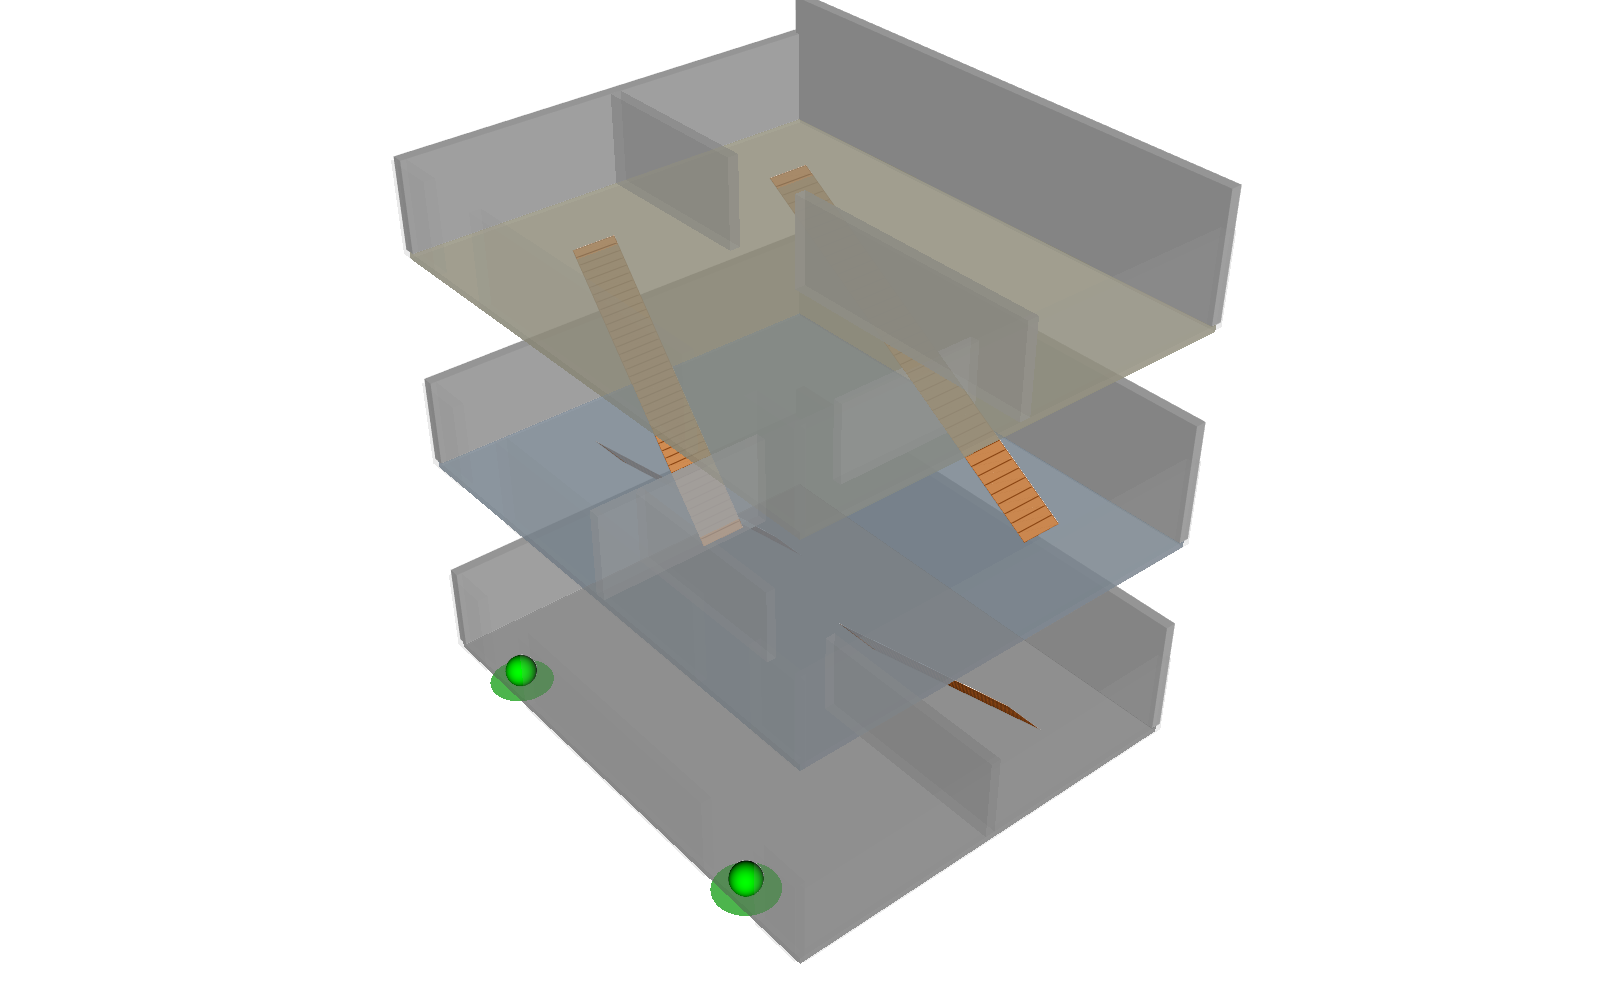

In [18]:
# =============================================================
# BUILDING VISUALIZATION -- vedo (Colab offscreen compatible)
# =============================================================

import numpy as np
import vedo
vedo.settings.default_backend = 'vtk'

# =============================================================
# SECTION 1: BUILDING PARAMETERS
# Must match the simulation cell exactly.
# =============================================================

H       = 5.0
FLOOR_W = 12.0
FLOOR_D = 10.0
FLOOR_T = 0.15
WALL_H  = 2.0
WALL_T  = 0.25
RAMP_W  = 0.5    # ramp half-width r (eq 4.9) -- matches simulation cell

Z = [0.0, H, 2 * H]   # top surface height of each floor slab

EXITS_2D = [
    np.array([2.0,  0.3]),   # y=0.3 matches simulation EXITS_2D
    np.array([10.0, 0.3]),
]

RAMPS = [
    # Ground <-> First -- vertical runs (along y), left and right
    {'A': np.array([2.0,  3.0]), 'B': np.array([2.0,  8.0]),  'z0': Z[1], 'z1': Z[0], 'r': RAMP_W},
    {'A': np.array([10.0, 3.0]), 'B': np.array([10.0, 8.0]),  'z0': Z[1], 'z1': Z[0], 'r': RAMP_W},
    # First <-> Second -- ramp 3 B endpoint is x=6 (not x=10), matching simulation
    {'A': np.array([2.0,  3.0]), 'B': np.array([6.0,  3.0]),  'z0': Z[2], 'z1': Z[1], 'r': RAMP_W},
    {'A': np.array([2.0,  8.0]), 'B': np.array([10.0, 8.0]),  'z0': Z[2], 'z1': Z[1], 'r': RAMP_W},
]

# =============================================================
# SECTION 2: WALL HELPERS
# =============================================================

def make_h_wall(x0, x1, y, floor_idx, h=None, t=None, color='white', alpha=1.0):
    h = h or WALL_H
    t = t or WALL_T
    box = vedo.Box(pos=((x0+x1)/2, y, Z[floor_idx]+h/2), length=abs(x1-x0), width=t, height=h)
    return box.color(color).alpha(alpha)

def make_v_wall(x, y0, y1, floor_idx, h=None, t=None, color='white', alpha=1.0):
    h = h or WALL_H
    t = t or WALL_T
    box = vedo.Box(pos=(x, (y0+y1)/2, Z[floor_idx]+h/2), length=t, width=abs(y1-y0), height=h)
    return box.color(color).alpha(alpha)

# =============================================================
# SECTION 3: WALL LAYOUT
# Camera at low-y, high-x corner:
#   front (y=0) and right (x=FLOOR_W) -> translucent
#   back  (y=FLOOR_D) and left (x=0)  -> solid
# =============================================================

def build_walls():
    walls = []
    BACK_H   = 2.8
    TRANSP   = 0.10   # camera-facing walls -- nearly invisible
    SOLID    = 1.0    # back/left walls -- fully solid
    INTERIOR = 0.75   # interior dividers

    for fi in range(3):
        walls.append(make_h_wall(0, FLOOR_W, FLOOR_D, fi, h=BACK_H, alpha=SOLID))
        walls.append(make_v_wall(0, 0, FLOOR_D, fi, alpha=SOLID))
        walls.append(make_v_wall(FLOOR_W, 0, FLOOR_D, fi, alpha=TRANSP))
        walls.append(make_h_wall(0,    1.2,     0, fi, alpha=TRANSP))
        walls.append(make_h_wall(2.8,  9.2,     0, fi, alpha=TRANSP))
        walls.append(make_h_wall(10.8, FLOOR_W, 0, fi, alpha=TRANSP))

    # Ground floor: horizontal divider at y=5, gap x=5 to x=7
    walls.append(make_h_wall(0,   5.0,     5.0, 0, alpha=INTERIOR))
    walls.append(make_h_wall(7.0, FLOOR_W, 5.0, 0, alpha=INTERIOR))
    # First floor: vertical divider at x=6, gap y=4 to y=6
    walls.append(make_v_wall(6.0, 0,        4.0,     1, alpha=INTERIOR))
    walls.append(make_v_wall(6.0, 6.0, FLOOR_D,      1, alpha=INTERIOR))
    # Second floor: horizontal divider at y=5, gap x=4 to x=6
    walls.append(make_h_wall(0,   4.0,     5.0, 2, alpha=INTERIOR))
    walls.append(make_h_wall(6.0, FLOOR_W, 5.0, 2, alpha=INTERIOR))
    return walls

# =============================================================
# SECTION 4: FLOOR SLABS
# =============================================================

def make_floor_slab(floor_idx):
    colors = ['#d0d0d0', '#c8ddf0', '#f5f0d0']
    z_center = Z[floor_idx] - FLOOR_T / 2
    box = vedo.Box(
        pos=(FLOOR_W/2, FLOOR_D/2, z_center),
        length=FLOOR_W, width=FLOOR_D, height=FLOOR_T
    )
    return box.color(colors[floor_idx]).alpha(0.6)

# =============================================================
# SECTION 5: RAMPS
# eq 4.7: z = z0 + (z1 - z0) * t
# =============================================================

def make_ramp(ramp, n=40, color='sandybrown'):
    A, B   = ramp['A'], ramp['B']
    z0, z1 = ramp['z0'], ramp['z1']
    r      = ramp['r']
    v      = B - A
    v_n    = v / np.linalg.norm(v)
    perp   = np.array([-v_n[1], v_n[0]]) * r

    verts, faces = [], []
    for i in range(n + 1):
        t   = i / n
        z   = z0 + (z1 - z0) * t    # eq 4.7: linear height interpolation
        mid = A + t * v
        verts.append([mid[0] - perp[0], mid[1] - perp[1], z])
        verts.append([mid[0] + perp[0], mid[1] + perp[1], z])
    for i in range(n):
        il = 2 * i
        faces.append([il, il+1, il+3, il+2])

    mesh = vedo.Mesh([verts, faces])
    return mesh.color(color).alpha(1.0).lw(1).lc('saddlebrown')

# =============================================================
# SECTION 6: EXIT MARKERS
# =============================================================

def make_exit_markers():
    objects = []
    for xy in EXITS_2D:
        sphere = vedo.Sphere(pos=(xy[0], xy[1], Z[0] + 0.3), r=0.35).color('lime').alpha(1.0)
        disc   = vedo.Disc(pos=(xy[0], xy[1], Z[0] + 0.02), r1=0, r2=0.7, res=24).color('lime').alpha(0.7)
        objects += [sphere, disc]
    return objects

# =============================================================
# SECTION 7: ASSEMBLE + RENDER
# =============================================================

def build_building():
    objects  = [make_floor_slab(i) for i in range(3)]
    objects += build_walls()
    objects += [make_ramp(r) for r in RAMPS]
    objects += make_exit_markers()
    return objects

def render_building(filename='building.png', size=(1600, 1000)):
    objects = build_building()
    plotter = vedo.Plotter(offscreen=True, size=size, bg='white')
    plotter.add(objects)
    plotter.camera.SetPosition(FLOOR_W * 2.5, -FLOOR_D * 1.5, H * 5.5)
    plotter.camera.SetFocalPoint(FLOOR_W / 2, FLOOR_D / 2, H)
    plotter.camera.SetViewUp(0, 0, 1)
    plotter.render()
    plotter.screenshot(filename)
    plotter.close()
    print(f"Saved: {filename}")

render_building('building.png')

from IPython.display import Image
Image('building.png')

## 7. Simulation — Gradient Descent Evacuation

25 agents are initialized randomly: 9 on floor 2, 8 on floor 1, 8 on floor 0. Each agent has a 3D position $\mathbf{p} = (x,y,z)$ that evolves by gradient descent with momentum.

**Floor-aware cost:** The agent's floor is inferred from its $z$-coordinate at each step. The appropriate per-floor wall segments and ramp targets are selected accordingly.

**Gravity term:** A linear term $C_{\text{gravity}} = w_g \cdot z$ provides a persistent downward bias so agents on upper floors consistently prefer descending.

**Hard z-clamp:** After each gradient step, if an agent's $z$ falls below the computed surface height $z_{\text{surf}}(x,y)$, it is snapped back and its downward velocity is zeroed. This prevents phasing through floors — a problem that occurred when relying on the height cost alone with high $w_h$, which caused stiff-spring oscillation.

| Parameter | Value | Role |
|-----------|-------|------|
| `STEP_SIZE` | 0.08 | Gradient descent step size |
| `MOMENTUM` | 0.30 | Momentum coefficient |
| `MAX_STEP` | 0.20 | Step-size cap |
| `TAU` | 1.0 | Soft-min temperature (Eq. 5.12) |
| `WH` | 60.0 | Surface-adherence stiffness |
| `W_WALL` | 10.0 | Wall penalty weight |
| `R_WALL` | 0.65 | Wall penalty radius |
| `R_REPULSE` | 1.2 | Agent repulsion radius |
| `K_SOCIAL` | 3.5 | Agent repulsion strength |
| `W_GRAVITY` | 45.0 | Gravity term weight |

In [19]:
# =============================================================
# SECTION 8: SIMULATION — Gradient Descent Evacuation
# =============================================================

import numpy as np
import os, glob
import vedo
vedo.settings.default_backend = 'vtk'

N_AGENTS    = 25
N_STEPS     = 400
FRAME_EVERY = 3

STEP_SIZE = 0.08
MAX_STEP  = 0.20
MOMENTUM  = 0.30
EPSILON   = 1e-4
EXIT_TOL  = 1.2

TAU       = 1.0
W_GOAL    = 5.0
W_WALL    = 10.0
R_WALL    = 0.65
WH        = 60.0   # lowered from 250 — hard z-clamp handles floor enforcement now
W_SMOOTH  = 0.15
R_REPULSE = 1.2
K_SOCIAL  = 3.5
W_GRAVITY = 45.0

H       = 5.0
FLOOR_W = 12.0
FLOOR_D = 10.0
FLOOR_T = 0.15
WALL_T  = 0.25
WALL_H  = 2.0
RAMP_W  = 0.5
Z       = [0.0, H, 2.0 * H]

EXITS_3D = [np.array([2.0, 0.3, Z[0]]), np.array([10.0, 0.3, Z[0]])]
EXITS_2D = [np.array([2.0, 0.3]),        np.array([10.0, 0.3])]

# RAMPS now use consistent x=2/x=10 so they align with FLOOR_TARGETS exactly.
# Previous code had RAMPS[0]['A']=(3,3) but FLOOR_TARGETS[2][0]=(2,3) — 1-unit miss.
RAMPS = [
    {'A': np.array([2.0,  3.0]), 'B': np.array([2.0,  8.0]),  'z0': Z[1], 'z1': Z[0], 'r': RAMP_W},
    {'A': np.array([10.0, 3.0]), 'B': np.array([10.0, 8.0]),  'z0': Z[1], 'z1': Z[0], 'r': RAMP_W},
    {'A': np.array([2.0,  3.0]), 'B': np.array([6.0, 3.0]),  'z0': Z[2], 'z1': Z[1], 'r': RAMP_W},
    {'A': np.array([2.0,  8.0]), 'B': np.array([10.0, 8.0]),  'z0': Z[2], 'z1': Z[1], 'r': RAMP_W},
]

FLOOR_TARGETS = {
     2: [np.array([2.,3.]), np.array([2.,8.])],
    1: [np.array([2.,5.5]), np.array([10.,5.5])],
    0: EXITS_2D,
}

_W = FLOOR_W; _D = FLOOR_D
WALLS_PER_FLOOR = {
    0: [(np.array([0.,0.]),np.array([1.2,0.])),(np.array([2.8,0.]),np.array([9.2,0.])),(np.array([10.8,0.]),np.array([_W,0.])),(np.array([0.,_D]),np.array([_W,_D])),(np.array([0.,0.]),np.array([0.,_D])),(np.array([_W,0.]),np.array([_W,_D]))],
    1: [(np.array([0.,0.]),np.array([1.2,0.])),(np.array([2.8,0.]),np.array([9.2,0.])),(np.array([10.8,0.]),np.array([_W,0.])),(np.array([0.,_D]),np.array([_W,_D])),(np.array([0.,0.]),np.array([0.,_D])),(np.array([_W,0.]),np.array([_W,_D])),(np.array([6.,0.]),np.array([6.,4.])),(np.array([6.,6.]),np.array([6.,_D]))],
    2: [(np.array([0.,0.]),np.array([_W,0.])),(np.array([0.,_D]),np.array([_W,_D])),(np.array([0.,0.]),np.array([0.,_D])),(np.array([_W,0.]),np.array([_W,_D])),(np.array([0.,5.]),np.array([4.,5.])),(np.array([6.,5.]),np.array([_W,5.]))],
}

def z_surface_global(x_2d, z_current):
    ramp_candidates = []
    for ramp in RAMPS:
        dist, u = point_to_segment_projection(x_2d, ramp['A'], ramp['B'])
        if dist > ramp['r']:
            continue
        z_ramp = ramp['z0'] + (ramp['z1'] - ramp['z0']) * u
        z_hi   = max(ramp['z0'], ramp['z1'])
        if abs(z_current - z_hi) <= H * 0.7:
            ramp_candidates.append(z_ramp)
    if ramp_candidates:
        return min(ramp_candidates, key=lambda z: abs(z - z_current))
    return min(Z, key=lambda z: abs(z - z_current))

def get_targets(pos):
    x_2d = pos[:2]; z = pos[2]
    best = None; best_d = RAMP_W + 1.0
    for ramp in RAMPS:
        dist, u = point_to_segment_projection(x_2d, ramp['A'], ramp['B'])
        if dist > ramp['r']:
            continue
        z_hi = max(ramp['z0'], ramp['z1'])
        if abs(z - z_hi) <= H * 0.7 and dist < best_d:
            best_d = dist; best = ramp
    if best is not None:
        return [best['B']]
    if z < H * 0.5:   return FLOOR_TARGETS[0]
    elif z < H * 1.5: return FLOOR_TARGETS[1]
    else:              return FLOOR_TARGETS[2]

def z_to_floor(z):
    if z < H * 0.5:   return 0
    elif z < H * 1.5: return 1
    else:              return 2

def height_cost(pos):
    return WH * (pos[2] - z_surface_global(pos[:2], pos[2])) ** 2

def gravity_cost(pos):
    return W_GRAVITY * pos[2]

def goal_cost(pos):
    targets = get_targets(pos)
    costs   = np.array([np.sum((pos[:2] - t) ** 2) for t in targets])
    cs      = costs - costs.min()
    return W_GOAL * (-TAU * np.log(np.sum(np.exp(-cs / TAU))) + costs.min() / TAU)

def _cost_for_agent(pos, pos_prev, all_pos, idx):
    fi = z_to_floor(pos[2])
    return (goal_cost(pos)
          + wall_cost_3d(pos, WALLS_PER_FLOOR[fi], W_WALL, R_WALL)
          + height_cost(pos)
          + gravity_cost(pos)
          + W_SMOOTH * smoothness_cost(pos, pos_prev)
          + repulsion_cost(pos, all_pos, idx, R_REPULSE, K_SOCIAL))

def _gradient(pos, pos_prev, all_pos, idx):
    grad = np.zeros(3)
    for dim in range(3):
        pp = pos.copy(); pp[dim] += EPSILON
        pm = pos.copy(); pm[dim] -= EPSILON
        grad[dim] = (_cost_for_agent(pp, pos_prev, all_pos, idx) -
                     _cost_for_agent(pm, pos_prev, all_pos, idx)) / (2 * EPSILON)
    return grad

rng = np.random.default_rng(42)
def _rp(fi):
    m=1.5; return np.array([rng.uniform(m,FLOOR_W-m), rng.uniform(m,FLOOR_D-m), Z[fi]], dtype=float)

positions      = np.array([_rp(2) for _ in range(9)] + [_rp(1) for _ in range(8)] + [_rp(0) for _ in range(8)], dtype=float)
prev_positions = positions.copy()
velocities     = np.zeros_like(positions)
evacuated      = np.zeros(N_AGENTS, dtype=bool)
AGENT_COLORS   = ['#e74c3c']*9 + ['#3498db']*8 + ['#2ecc71']*8
AGENT_R        = 0.28

def _build_static_objects():
    objs = []
    for fi, col in enumerate(['#d0d0d0','#c8ddf0','#f5f0d0']):
        b=vedo.Box(pos=(FLOOR_W/2,FLOOR_D/2,Z[fi]-FLOOR_T/2),length=FLOOR_W,width=FLOOR_D,height=FLOOR_T)
        b.color(col).alpha(0.6); objs.append(b)
    def _hw(x0,x1,y,fi,h=WALL_H,al=1.0):
        bx=vedo.Box(pos=((x0+x1)/2,y,Z[fi]+h/2),length=abs(x1-x0),width=WALL_T,height=h)
        bx.color('white').alpha(al); return bx
    def _vw(x,y0,y1,fi,h=WALL_H,al=1.0):
        bx=vedo.Box(pos=(x,(y0+y1)/2,Z[fi]+h/2),length=WALL_T,width=abs(y1-y0),height=h)
        bx.color('white').alpha(al); return bx
    for fi in range(3):
        objs += [_hw(0,FLOOR_W,FLOOR_D,fi,h=2.8,al=1.0),_vw(0,0,FLOOR_D,fi,al=1.0),
                 _vw(FLOOR_W,0,FLOOR_D,fi,al=0.10),_hw(0,1.2,0,fi,al=0.10),
                 _hw(2.8,9.2,0,fi,al=0.10),_hw(10.8,FLOOR_W,0,fi,al=0.10)]
    objs += [_vw(6,0,4,1,al=0.75),_vw(6,6,FLOOR_D,1,al=0.75),
             _hw(0,4,5,2,al=0.75),_hw(6,FLOOR_W,5,2,al=0.75)]
    for ramp in RAMPS:
        A,B,z0,z1,r=ramp['A'],ramp['B'],ramp['z0'],ramp['z1'],ramp['r']
        v=B-A; vn=v/np.linalg.norm(v); perp=np.array([-vn[1],vn[0]])*r
        n=40; verts=[]; faces=[]
        for i in range(n+1):
            tt=i/n; zz=z0+(z1-z0)*tt; mid=A+tt*v
            verts+=[[mid[0]-perp[0],mid[1]-perp[1],zz],[mid[0]+perp[0],mid[1]+perp[1],zz]]
        for i in range(n):
            il=2*i; faces.append([il,il+1,il+3,il+2])
        m=vedo.Mesh([verts,faces]); m.color('sandybrown').alpha(1.0).lw(1).lc('saddlebrown'); objs.append(m)
    for xy in [[2.,0.],[10.,0.]]:
        s=vedo.Sphere(pos=(xy[0],xy[1],Z[0]+0.3),r=0.35); s.color('lime'); objs.append(s)
        d=vedo.Disc(pos=(xy[0],xy[1],Z[0]+0.02),r1=0,r2=0.7,res=24); d.color('lime').alpha(0.7); objs.append(d)
    return objs

static_objects = _build_static_objects()

FRAME_DIR='/tmp/evac_frames'
os.makedirs(FRAME_DIR,exist_ok=True)
for f in glob.glob(f'{FRAME_DIR}/*.png'): os.remove(f)
frame_idx=0

def render_frame(step):
    global frame_idx
    plt=vedo.Plotter(offscreen=True,size=(1200,800),bg='white')
    plt.add(static_objects)
    for i,(pos,evac) in enumerate(zip(positions,evacuated)):
        if evac: continue
        s=vedo.Sphere(pos=(pos[0],pos[1],pos[2]+AGENT_R),r=AGENT_R)
        s.color(AGENT_COLORS[i]).alpha(1.0); plt.add(s)
    n_evac=int(evacuated.sum())
    plt.add(vedo.Text2D(f"Step {step:>3d}/{N_STEPS}   Evacuated: {n_evac}/{N_AGENTS}   [Red=Floor2  Blue=Floor1  Green=Floor0]",pos='top-left',s=0.75,c='black'))
    plt.camera.SetPosition(FLOOR_W*2.5,-FLOOR_D*1.5,H*5.5)
    plt.camera.SetFocalPoint(FLOOR_W/2,FLOOR_D/2,H)
    plt.camera.SetViewUp(0,0,1)
    plt.render(); plt.screenshot(f'{FRAME_DIR}/frame_{frame_idx:04d}.png'); plt.close()
    frame_idx+=1

print("Starting evacuation simulation...")
print(f"  {N_AGENTS} agents | {N_STEPS} steps | frame every {FRAME_EVERY} steps")
render_frame(0)

for step in range(1, N_STEPS+1):
    all_pos = positions.copy()
    for i in range(N_AGENTS):
        if evacuated[i]: continue
        pos  = positions[i]
        prev = prev_positions[i]

        grad = _gradient(pos, prev, all_pos, i)
        velocities[i] = MOMENTUM * velocities[i] - STEP_SIZE * grad
        spd = np.linalg.norm(velocities[i])
        if spd > MAX_STEP:
            velocities[i] = velocities[i] / spd * MAX_STEP

        prev_positions[i] = positions[i].copy()
        positions[i]      = positions[i] + velocities[i]

        # xy boundary
        positions[i][0] = np.clip(positions[i][0], 0.1, FLOOR_W - 0.1)
        positions[i][1] = np.clip(positions[i][1], 0.1, FLOOR_D - 0.1)

        # Hard z-clamp: agents cannot pass through the surface they are on.
        # This is the definitive fix for "phasing through floors".
        # WH=250 previously caused stiff-spring oscillation (±MAX_STEP every step)
        # because the spring gradient was always larger than MAX_STEP.
        # The clamp is a direct position correction — physically correct and stable.
        z_surf = z_surface_global(positions[i][:2], positions[i][2])
        if positions[i][2] < z_surf:
            positions[i][2] = z_surf
            velocities[i][2] = max(velocities[i][2], 0.0)  # kill downward velocity on contact

        positions[i][2] = np.clip(positions[i][2], -0.1, 2*H + 0.1)

        for ex in EXITS_3D:
            if np.linalg.norm(positions[i][:2]-ex[:2]) < EXIT_TOL and positions[i][2] < H*0.3:
                evacuated[i] = True; break

    if step % FRAME_EVERY == 0 or step == N_STEPS:
        print(f"  Step {step:>3d}: {int(evacuated.sum())}/{N_AGENTS} evacuated")
        render_frame(step)

print(f"\nDone. {int(evacuated.sum())}/{N_AGENTS} agents evacuated.")
print(f"{frame_idx} frames saved to {FRAME_DIR}")
print("Run the next cell to encode the video.")

Starting evacuation simulation...
  25 agents | 400 steps | frame every 3 steps
  Step   3: 0/25 evacuated
  Step   6: 0/25 evacuated
  Step   9: 0/25 evacuated
  Step  12: 0/25 evacuated
  Step  15: 0/25 evacuated
  Step  18: 0/25 evacuated
  Step  21: 0/25 evacuated
  Step  24: 1/25 evacuated
  Step  27: 1/25 evacuated
  Step  30: 1/25 evacuated
  Step  33: 2/25 evacuated
  Step  36: 5/25 evacuated
  Step  39: 5/25 evacuated
  Step  42: 5/25 evacuated
  Step  45: 5/25 evacuated
  Step  48: 6/25 evacuated
  Step  51: 7/25 evacuated
  Step  54: 7/25 evacuated
  Step  57: 7/25 evacuated
  Step  60: 7/25 evacuated
  Step  63: 8/25 evacuated
  Step  66: 8/25 evacuated
  Step  69: 8/25 evacuated
  Step  72: 8/25 evacuated
  Step  75: 8/25 evacuated
  Step  78: 9/25 evacuated
  Step  81: 9/25 evacuated
  Step  84: 9/25 evacuated
  Step  87: 9/25 evacuated
  Step  90: 9/25 evacuated
  Step  93: 10/25 evacuated
  Step  96: 11/25 evacuated
  Step  99: 11/25 evacuated
  Step 102: 11/25 evacuate

## 8. Video Export

This cell encodes the frames saved in `/tmp/evac_frames/` into a single MP4 file.
Run it after the simulation cell finishes.


In [20]:
# =============================================================
# SECTION 9: VIDEO EXPORT — frames → MP4
# Run this cell after the simulation cell finishes.
# Requires: !pip install imageio[ffmpeg]
# =============================================================

import imageio.v2 as iio
import glob, os
from IPython.display import Video, display

FRAME_DIR  = '/tmp/evac_frames'
OUTPUT_MP4 = 'evacuation.mp4'
FPS        = 12    # increase for faster playback, decrease for slower

frame_files = sorted(glob.glob(f'{FRAME_DIR}/frame_*.png'))
print(f"Found {len(frame_files)} frames → encoding at {FPS} fps...")

writer = iio.get_writer(OUTPUT_MP4, fps=FPS, quality=8)
for fp in frame_files:
    writer.append_data(iio.imread(fp))
writer.close()

size_mb = os.path.getsize(OUTPUT_MP4) / 1e6
print(f"Saved: {OUTPUT_MP4}  ({size_mb:.1f} MB)")
display(Video(OUTPUT_MP4, embed=True, width=900))

Found 135 frames → encoding at 12 fps...
Saved: evacuation.mp4  (0.3 MB)


## 9. Discussion & Results


### Observations

**Oscilations:** By varying the gravity weight and the surface-adherence 
parameter `wh`, agents can be made to bob up and down continuously on the 
ramp surface. This happens because the height cost acts like a spring — if 
`wh` is too large the restoring force overshoots each step, causing the agent 
to bounce past the surface repeatedly. With the values used here (`wh=60`, 
`W_GRAVITY=45`) this effect is reduced to a nearly unnoticeable level.

**Ramp traversal:** Intresting bugs can occur with the ramp when the goals and ramp exits/entrances misalign.During testing and fine tuning a recoccuring bug would occur in which particles would phase thorugh the top floor to the second floor but not the second floor to the bottom floor, this was the most difficult bug to diagnose as first i belived it to be due to the values but due to inconsitancy it simply couldent be.After some research and testing I disocvered the issue and as shown the ramps work exactly as intended

**Exit repulsion:** An interesting interaction emerges between the 
goal cost and the wall cost near the exits. As agents approach an exit, the 
wall segments on either side of the gap create a repulsion force that 
partially opposes the goal attraction. Before fine-tuning, this sometimes 
produced a near-equilibrium state where an agent would stall just outside the 
exit, effectively orbiting the goal position. This occurred most often with 
the last remaining agents, since by that point the social repulsion force from 
other agents — which had previously been pushing them toward the exit — was 
gone. After adjusting `R_WALL` and `W_WALL`, agents slow slightly near the 
exit but always pass through within a few steps.

### Results

All 25 agents successfully evacuated to the two ground-floor exits. Agents 
distributed naturally between the two exits based on their starting position, 
with no hard-coded exit assignment — the soft-min cost function (Eq. 5.9) 
produced this split as emergent behaviour. No agents merged, got permanently 
stuck, or phased through floors in the final version. The last agent evacuated 
by approximately step 380 out of 400.